# **Supervised Classification: Decision Trees, SVM, and Naive Bayes | Assignment (DA-AG-009)**

# **THEORY QUESTION**

### **1. What is Information Gain, and how is it used in Decision Trees?**

**Answer**:

**Information Gain (IG)** measures how much the **uncertainty (impurity) about the class label is reduced** after splitting the data on a feature. It is the difference between the entropy of the parent node and the weighted average entropy of the child nodes:

`IG(S, A) = Entropy(S) − Σ (|Sᵥ| / |S|) × Entropy(Sᵥ)`

where `Entropy(S) = − Σ pᵢ log₂(pᵢ)` and `Sᵥ` is the subset of S for which feature A has value v.

🔹 **How it is used in Decision Trees (ID3 / C4.5)**
1. Calculate the entropy of the current node.
2. For every candidate feature (and threshold for numeric features), calculate the information gain of the split.
3. Choose the feature with the **highest information gain** as the splitting feature for that node.
4. Repeat recursively on each child until the nodes are pure or a stopping rule is reached.

🔹 **Remark**: IG is biased towards features with many distinct values (e.g. ID numbers); C4.5 corrects this with **Gain Ratio**.

The cell below calculates IG by hand for the classic "play tennis" data (9 Yes, 5 No) split on *Outlook*.

In [1]:
import numpy as np

def entropy(labels):
    p = np.bincount(labels) / len(labels)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

# 1 = Play, 0 = Don't play
parent   = [1]*9 + [0]*5
sunny    = [1]*2 + [0]*3
overcast = [1]*4
rainy    = [1]*3 + [0]*2

H_parent = entropy(parent)
H_children = sum(len(s) / len(parent) * entropy(s) for s in (sunny, overcast, rainy))
print(f"Entropy of parent node     : {H_parent:.4f}")
print(f"Weighted entropy of children: {H_children:.4f}")
print(f"Information Gain (Outlook) : {H_parent - H_children:.4f}")

Entropy of parent node     : 0.9403
Weighted entropy of children: 0.6935
Information Gain (Outlook) : 0.2467


### **2. What is the difference between Gini Impurity and Entropy?**

**Answer**:

Both are **impurity measures** used to decide the best split in a decision tree. A node is **pure** when it contains only one class.

| Aspect | Gini Impurity | Entropy |
|---|---|---|
| **Formula** | `Gini = 1 − Σ pᵢ²` | `Entropy = − Σ pᵢ log₂(pᵢ)` |
| **Range (binary)** | 0 to 0.5 | 0 to 1 |
| **Meaning** | Probability of misclassifying a randomly chosen sample if labelled by the node's class distribution | Amount of disorder / information content (in bits) |
| **Computation** | Faster (no logarithm) | Slightly slower (uses log) |
| **Used by** | CART (scikit-learn default) | ID3, C4.5 (via Information Gain) |
| **Behaviour** | Tends to isolate the most frequent class; favours larger, purer partitions | Slightly more sensitive to changes in class probabilities; can produce more balanced trees |
| **Strength** | Efficient, works well on large datasets | More theoretically grounded (information theory) |
| **Weakness** | Less sensitive to small probability differences | More expensive to compute |

🔹 **When to use**: In practice both give very similar trees and accuracy. Use **Gini** as a fast default for large datasets; use **Entropy** when you want information-theoretic splits (or when classes are very imbalanced and you want a more sensitive measure).

criterion = gini     test accuracy = 0.9240
criterion = entropy  test accuracy = 0.9532


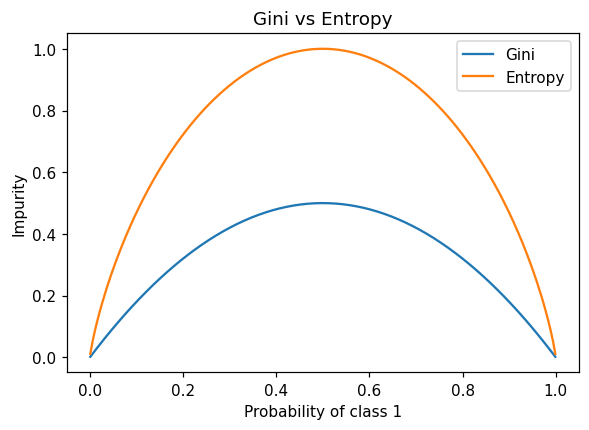

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. Impurity curves for a binary node
p = np.linspace(0.001, 0.999, 200)
gini = 1 - p**2 - (1 - p)**2
ent = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
plt.figure(figsize=(6, 4))
plt.plot(p, gini, label="Gini"); plt.plot(p, ent, label="Entropy")
plt.xlabel("Probability of class 1"); plt.ylabel("Impurity"); plt.title("Gini vs Entropy"); plt.legend(); plt.show()

# 2. Same data, both criteria
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
for crit in ["gini", "entropy"]:
    t = DecisionTreeClassifier(criterion=crit, max_depth=4, random_state=42).fit(X_tr, y_tr)
    print(f"criterion = {crit:<8} test accuracy = {t.score(X_te, y_te):.4f}")

**Interpretation**: Both criteria give high and similar accuracy. The small difference between them depends on the dataset and the split, and is not a general rule that one criterion is better.

### **3. What is Pre-Pruning in Decision Trees?**

**Answer**:

**Pre-pruning (early stopping)** means **stopping the growth of the tree before it becomes fully grown**, so that it does not memorise noise in the training data (overfitting). A split is not made if it fails a stopping condition.

🔹 **Common pre-pruning parameters (scikit-learn)**
* `max_depth`: maximum depth of the tree.
* `min_samples_split`: minimum samples a node must have to be split.
* `min_samples_leaf`: minimum samples required in a leaf.
* `max_leaf_nodes`: maximum number of leaf nodes.
* `min_impurity_decrease`: a split is made only if it reduces impurity by at least this value.

🔹 **Advantages**: faster training, smaller and more interpretable tree, less overfitting.
🔹 **Disadvantage**: may stop too early (underfitting), because a split that looks useless now might lead to good splits later (horizon effect).

**Post-pruning** is the opposite approach: grow the full tree first, then remove weak branches (e.g. cost-complexity pruning with `ccp_alpha`).

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

full = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)                                       # no pruning
pruned = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42).fit(X_tr, y_tr)    # pre-pruned

for name, t in [("Unpruned", full), ("Pre-pruned (max_depth=3, min_samples_leaf=5)", pruned)]:
    print(f"{name}\n  depth = {t.get_depth()}, leaves = {t.get_n_leaves()}, "
          f"train acc = {t.score(X_tr, y_tr):.4f}, test acc = {t.score(X_te, y_te):.4f}")

Unpruned
  depth = 6, leaves = 16, train acc = 1.0000, test acc = 0.9181
Pre-pruned (max_depth=3, min_samples_leaf=5)
  depth = 3, leaves = 7, train acc = 0.9724, test acc = 0.9357


**Interpretation**: Pre-pruning gives a much smaller tree (7 leaves instead of 16) with lower training accuracy but higher test accuracy, which shows reduced overfitting.

# **PRACTICAL QUESTIONS**

### **4. Write a Python program to train a Decision Tree Classifier using Gini Impurity as the criterion and print the feature importances (practical).**

**Answer**:

In [4]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load data
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Train Decision Tree with Gini impurity
clf = DecisionTreeClassifier(criterion="gini", random_state=42)
clf.fit(X_train, y_train)

print("Test accuracy:", round(accuracy_score(y_test, clf.predict(X_test)), 4))

# Feature importances
importances = pd.Series(clf.feature_importances_, index=iris.feature_names).sort_values(ascending=False)
print("\nFeature importances:")
print(importances.round(4))

Test accuracy: 0.9333

Feature importances:
petal length (cm)    0.5412
petal width (cm)     0.4303
sepal width (cm)     0.0286
sepal length (cm)    0.0000
dtype: float64


**Interpretation**: The most important feature is **petal length (cm)** (importance = 0.54). Feature importances sum to 1; they show how much each feature reduced the Gini impurity across the tree's splits.

### **5. What is a Support Vector Machine (SVM)?**

**Answer**:

A **Support Vector Machine (SVM)** is a supervised learning algorithm used mainly for **classification** (and also regression, SVR). It finds the **optimal separating hyperplane** that divides the classes with the **maximum margin**, i.e. the largest possible distance between the hyperplane and the nearest points of each class.

🔹 **Key terms**
* **Hyperplane**: the decision boundary (a line in 2D, a plane in 3D, ...), `w·x + b = 0`.
* **Support vectors**: the training points closest to the hyperplane; only they define the boundary.
* **Margin**: the gap between the hyperplane and the support vectors; SVM maximises it for better generalisation.
* **Soft margin / C parameter**: allows some misclassification. Small C gives a wider margin (more tolerance); large C fits training data more strictly (risk of overfitting).
* **Kernel**: lets SVM handle non-linear data (see Question 6).

🔹 **Advantages**: effective in high dimensions, works well with clear margins, memory efficient (uses only support vectors).
🔹 **Disadvantages**: slow on very large datasets, needs feature scaling, sensitive to the choice of kernel and hyper-parameters, no direct probability output.

### **6. What is the Kernel Trick in SVM?**

**Answer**:

Many datasets are **not linearly separable** in their original space. The **kernel trick** lets SVM separate them by implicitly mapping the data into a **higher-dimensional space** where a linear hyperplane can separate the classes, **without actually computing the new coordinates**. SVM only needs dot products between points, and a kernel function `K(x, x') = φ(x)·φ(x')` returns that dot product of the mapped points directly from the original features. This saves a huge amount of computation.

🔹 **Common kernels**
| Kernel | Formula | Use |
|---|---|---|
| **Linear** | `K = x·x'` | Linearly separable data, many features (e.g. text) |
| **Polynomial** | `K = (γ x·x' + r)^d` | Curved boundaries of a given degree |
| **RBF (Gaussian)** | `K = exp(−γ ‖x − x'‖²)` | Default for general non-linear data |
| **Sigmoid** | `K = tanh(γ x·x' + r)` | Neural-network-like behaviour |

The demo below uses concentric circles, which no straight line can separate.

linear kernel accuracy: 0.597
rbf    kernel accuracy: 1.000


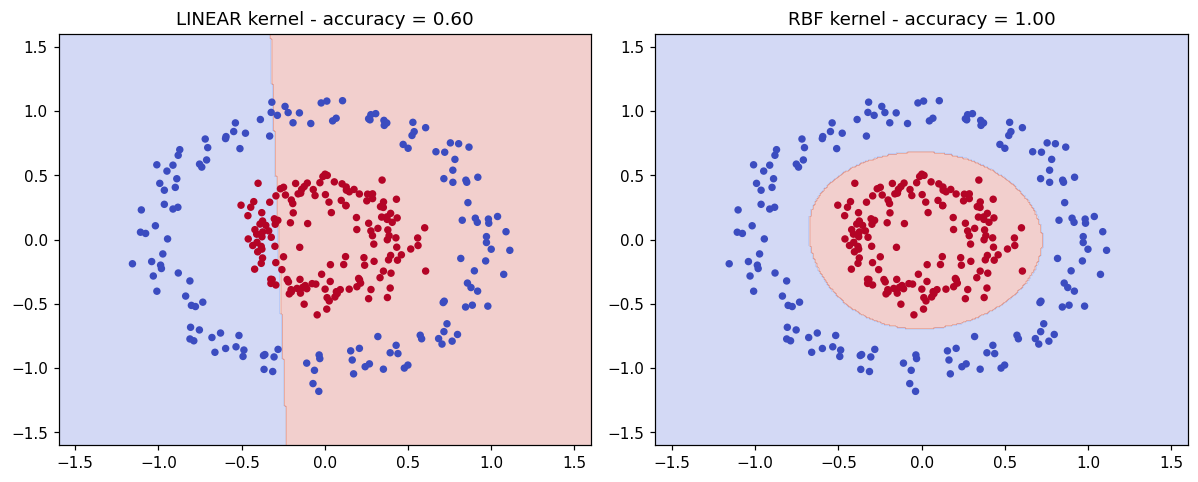

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC

X, y = make_circles(n_samples=300, factor=0.4, noise=0.08, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    clf = SVC(kernel=kernel, C=1).fit(X, y)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm"); ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15)
    ax.set_title(f"{kernel.upper()} kernel - accuracy = {clf.score(X, y):.2f}")
    print(f"{kernel:<6} kernel accuracy: {clf.score(X, y):.3f}")
plt.tight_layout(); plt.show()

**Interpretation**: The linear kernel cannot separate the circles (accuracy about 0.60), while the RBF kernel, which uses the kernel trick, separates them perfectly (accuracy 1.00).

### **7. Write a Python program to train two SVM classifiers with Linear and RBF kernels on the Wine dataset, then compare their accuracies.**

**Answer**:

In [6]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load Wine dataset and split
X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

def compare(Xtr, Xte, label):
    print(label)
    accs = {}
    for kernel in ["linear", "rbf"]:
        model = SVC(kernel=kernel, random_state=42)
        model.fit(Xtr, y_train)
        accs[kernel] = accuracy_score(y_test, model.predict(Xte))
        print(f"  SVC(kernel='{kernel}') accuracy = {accs[kernel]:.4f}")
    return accs

# 1) Same dataset, raw features
acc_raw = compare(X_train, X_test, "Without feature scaling:")

# 2) With StandardScaler (recommended for SVM)
scaler = StandardScaler().fit(X_train)
acc_scaled = compare(scaler.transform(X_train), scaler.transform(X_test), "\nWith StandardScaler:")

better = max(acc_scaled, key=acc_scaled.get)
print(f"\nBest kernel after scaling: {better}")

Without feature scaling:
  SVC(kernel='linear') accuracy = 0.9444
  SVC(kernel='rbf') accuracy = 0.6667

With StandardScaler:
  SVC(kernel='linear') accuracy = 0.9630
  SVC(kernel='rbf') accuracy = 0.9815

Best kernel after scaling: rbf


**Interpretation**: Without scaling, linear = 0.9444 and RBF = 0.6667. After scaling, linear = 0.9630 and RBF = 0.9815. SVM is distance based, so features with large ranges (like *proline* in Wine) dominate unless the data is scaled; the RBF kernel in particular is very sensitive to this. Once scaled, both kernels do well; the gap between them is only about one sample out of 54 test samples, so it should not be over-interpreted.

### **8. What is the Naïve Bayes classifier, and why is it called "Naïve"?**

**Answer**:

**Naïve Bayes** is a probabilistic classification algorithm based on **Bayes' theorem**. For a sample with features x₁ ... xₙ it computes the probability of each class and predicts the class with the highest posterior probability:

`P(C | x₁...xₙ) = P(C) · P(x₁...xₙ | C) / P(x₁...xₙ)`

Since `P(x₁...xₙ)` is the same for all classes, it predicts `argmax_C  P(C) · Π P(xᵢ | C)`.

🔹 **Why "Naïve"?** Because it makes the **naïve (strong) assumption that all features are conditionally independent of each other given the class**: `P(x₁...xₙ | C) = P(x₁|C) · P(x₂|C) ... P(xₙ|C)`. In real data features are often correlated (e.g. height and weight), so the assumption is rarely true, yet the classifier still works surprisingly well in practice.

🔹 **Strengths**: very fast, needs little training data, handles high-dimensional data, good for text classification and spam filtering. 
🔹 **Weaknesses**: independence assumption, zero-frequency problem (solved by Laplace smoothing), probability estimates can be poorly calibrated.

### **9. Explain the differences between Gaussian Naïve Bayes, Multinomial Naïve Bayes, and Bernoulli Naïve Bayes**

**Answer**:

| Aspect | Gaussian NB | Multinomial NB | Bernoulli NB |
|---|---|---|---|
| **Feature type** | Continuous (real-valued) | Discrete counts / frequencies | Binary (0/1: present or absent) |
| **Assumed distribution** | Normal (Gaussian) distribution of each feature per class, using mean μ and variance σ² | Multinomial distribution of counts | Bernoulli (binary) distribution |
| **Likelihood** | `P(xᵢ\|C) = 1/√(2πσ²) · exp(−(xᵢ−μ)²/2σ²)` | `P(xᵢ\|C) ∝ (count of feature i in class C + α) / (total count in C + α·n)` | `P(xᵢ\|C) = p·xᵢ + (1−p)(1−xᵢ)` (also penalises absent features) |
| **Typical use** | Iris, medical measurements (e.g. breast cancer), sensor data | Text classification with word counts / TF-IDF, document categorisation | Text with word presence/absence, short messages, binary features |
| **scikit-learn class** | `GaussianNB` | `MultinomialNB` | `BernoulliNB` |

**Key difference**: Gaussian handles *continuous* data, Multinomial uses *how many times* a feature occurs, and Bernoulli only uses *whether* a feature occurs (and explicitly models absence).

In [7]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# Gaussian NB: continuous features (Iris)
X, y = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("GaussianNB    on Iris (continuous)   accuracy:", round(GaussianNB().fit(Xtr, ytr).score(Xte, yte), 4))

# Multinomial / Bernoulli NB: tiny spam-vs-ham text example
texts = ["win free money now", "free prize claim now", "cheap loans win cash", "limited offer free gift",
         "meeting at noon tomorrow", "project report attached", "lunch with the team", "see you at the meeting"]
labels = np.array([1, 1, 1, 1, 0, 0, 0, 0])            # 1 = spam, 0 = ham
new = ["free cash prize", "team meeting report"]

counts = CountVectorizer()
Xc = counts.fit_transform(texts)
mnb = MultinomialNB().fit(Xc, labels)
print("MultinomialNB (word counts)  ->", mnb.predict(counts.transform(new)), "(1 = spam, 0 = ham)")

binary = CountVectorizer(binary=True)
Xb = binary.fit_transform(texts)
bnb = BernoulliNB().fit(Xb, labels)
print("BernoulliNB   (word presence) ->", bnb.predict(binary.transform(new)), "(1 = spam, 0 = ham)")

GaussianNB    on Iris (continuous)   accuracy: 0.9111
MultinomialNB (word counts)  -> [1 0] (1 = spam, 0 = ham)
BernoulliNB   (word presence) -> [1 0] (1 = spam, 0 = ham)


### **10. Write a Python program to train a Gaussian Naïve Bayes classifier on the Breast Cancer dataset and evaluate accuracy.**

**Answer**:

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target
print("Dataset shape:", X.shape, "| classes:", [str(c) for c in data.target_names])

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Evaluate
y_pred = gnb.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {acc:.4f}  ({acc*100:.2f}%)")
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=data.target_names))

Dataset shape: (569, 30) | classes: ['malignant', 'benign']

Accuracy: 0.9386  (93.86%)

Confusion matrix:
 [[38  4]
 [ 3 69]]

Classification report:
               precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



**Interpretation**: Gaussian Naïve Bayes reaches an accuracy of about **93.9%** on the held-out test set. Even though the 30 tumour measurements are correlated (violating the independence assumption), the classifier performs well and is extremely fast to train.